<a href="https://colab.research.google.com/github/JohanaSalas1978/ConnectaTel-Analysis/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

In [ ]:
# Importar librerías
from scipy.stats import pointbiserialr
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np





### Cargar Dataset

In [ ]:

# Cargar el dataset y explorar datos
df = df=pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df=pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
* `edad`
* `nivel_ingreso`
* `visitas_mes`
* `compras_mes`
* `gasto_publicidad_dirigida`
* `satisfaccion`
* `ingreso_anual`


La mayoría de estas variables presentan tipos de datos adecuados.
La columna `edad` está almacenada como `float64` aunque representa años enteros; no afecta el análisis de correlación, por lo que no se modifica. La columna `satisfaccion` es una escala de 1 a 5 con decimales y se trata como variable numérica continua.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
# edad: son años enteros, se pasa de float a entero
if (df['edad'] % 1 == 0).all():
    df['edad'] = df['edad'].astype(int)

# Variables categóricas: se pasan a tipo category
for col in ['tipo_dispositivo', 'region']:
    df[col] = df[col].astype('category')

df.dtypes


id_cliente                     object
edad                            int64
nivel_ingreso                 float64
visitas_mes                     int64
compras_mes                     int64
gasto_publicidad_dirigida     float64
satisfaccion                  float64
miembro_premium                 int64
abandono                        int64
tipo_dispositivo             category
region                       category
ingreso_anual                 float64
dtype: object

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   id_cliente                 15000 non-null  object  
 1   edad                       15000 non-null  int64   
 2   nivel_ingreso              15000 non-null  float64 
 3   visitas_mes                15000 non-null  int64   
 4   compras_mes                15000 non-null  int64   
 5   gasto_publicidad_dirigida  15000 non-null  float64 
 6   satisfaccion               15000 non-null  float64 
 7   miembro_premium            15000 non-null  int64   
 8   abandono                   15000 non-null  int64   
 9   tipo_dispositivo           15000 non-null  category
 10  region                     15000 non-null  category
 11  ingreso_anual              15000 non-null  float64 
dtypes: category(2), float64(4), int64(5), object(1)
memory usage: 1.2+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

df[columnas_numericas].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.26,11.49,18.0,30.00,38.00,46.00,75.00
nivel_ingreso,15000.0,30019.70,9833.17,8000.0,23127.10,30023.74,36768.44,74790.84
visitas_mes,15000.0,10.03,3.16,1.0,8.00,10.00,12.00,25.00
compras_mes,15000.0,1.21,1.11,0.0,0.00,1.00,2.00,8.00
gasto_publicidad_dirigida,15000.0,20.15,10.88,0.0,12.31,19.73,27.29,75.51
satisfaccion,15000.0,3.60,0.69,1.0,3.10,3.60,4.10,5.00
ingreso_anual,15000.0,36.59,34.48,0.0,0.00,30.70,58.22,244.69


✍️**Diagnóstico:**

- **Calidad:** las 7 variables numéricas tienen 15,000 registros completos y sus rangos son coherentes: `edad` entre 18 y 75 años, `satisfaccion` entre 1 y 5, y sin valores negativos en visitas, compras, gasto o ingresos.
- **Ingreso con muchos ceros:** `ingreso_anual` tiene mínimo 0 y percentil 25 también en 0, es decir, al menos una cuarta parte de los clientes no generó ingreso. Lo mismo ocurre con `compras_mes`, cuyo percentil 25 es 0. Esto sugiere que los clientes sin compras tienen ingreso cero, algo que se confirmará más adelante.
- **Asimetría:** en `ingreso_anual` la media (36.59) es mayor que la mediana (30.70) y la desviación estándar (34.48) es casi igual a la media, lo que indica una distribución sesgada a la derecha, con algunos clientes de ingreso muy alto (máx. 244.69). `compras_mes` también muestra cola derecha (media 1.21, máx. 8).
- **Variables simétricas:** `edad`, `nivel_ingreso`, `visitas_mes` y `satisfaccion` tienen media y mediana muy cercanas, por lo que son aproximadamente simétricas.
- **Escalas distintas:** `nivel_ingreso` (media ≈ 30,000) e `ingreso_anual` (media ≈ 36.6) son variables diferentes y no deben confundirse.
- **Valores extremos:** `visitas_mes` (máx. 25) y `gasto_publicidad_dirigida` (máx. 75.51) tienen máximos alejados del percentil 75, pero son valores plausibles, por lo que no se eliminan.
- **Decisión:** no se requiere limpieza adicional en las variables numéricas. Como hay asimetría y muchos ceros, se usará Spearman como complemento de Pearson en el análisis de correlación.

### 2.1.3. Explorar variables binarias

In [ ]:

# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(f"{col}: {sorted(df[col].unique())}")
    print(df[col].value_counts().sort_index())
    print()


NameError: name 'df' is not defined

✍️ **Comentario:**

**Diagnóstico inicial de variables binarias**

* `miembro_premium` — Solo el 13.9% de los clientes (2,089 de 15,000) tiene suscripción premium, frente al 86.1% (12,911) que no. Hay desbalance entre grupos, pero el grupo premium tiene suficientes observaciones para compararlo con el resto. Más adelante se evaluará su relación con `ingreso_anual` mediante correlación punto biserial.
* `abandono` — El 15.1% de los clientes (2,261) abandonó la plataforma y el 84.9% (12,739) sigue activo. También hay desbalance, aunque ambos grupos son lo bastante grandes para el análisis. Será importante interpretarla con cuidado, porque el abandono puede ser consecuencia del bajo ingreso y no su causa.

Ambas columnas contienen únicamente los valores 0 y 1, sin nulos ni valores inesperados, por lo que no requieren transformación adicional.

#### 2.1.4 Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ['id_cliente', 'tipo_dispositivo', 'region']

for col in columnas_categoricas:
    print(f"{col}: {df[col].nunique()} valores únicos")


id_cliente: 15000 valores únicos
tipo_dispositivo: 3 valores únicos
region: 4 valores únicos


In [ ]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(f"--- {col} ---")
    print(pd.DataFrame({
        'clientes': df[col].value_counts(),
        'porcentaje': (df[col].value_counts(normalize=True) * 100).round(1)
    }))
    print()


--- tipo_dispositivo ---
            clientes  porcentaje
móvil           9818        65.5
escritorio      3720        24.8
tablet          1462         9.7

--- region ---
       clientes  porcentaje
norte      4395        29.3
oeste      3810        25.4
sur        3726        24.8
este       3069        20.5



✍️  **Comentario:**

**Diagnóstico inicial de variables categóricas**

* `tipo_dispositivo` — Tiene 3 categorías y está claramente concentrada en móvil, que agrupa al 65.5% de los clientes (9,818), seguida de escritorio con 24.8% (3,720) y tablet con 9.7% (1,462). Este desbalance es el detalle más relevante: al comparar `ingreso_anual` entre dispositivos habrá que interpretar con cuidado las diferencias, porque el grupo tablet es mucho más pequeño que el móvil.
* `region` — Tiene 4 categorías con tamaños más balanceados: norte es la más grande (29.3%, 4,395 clientes) y este la más pequeña (20.5%, 3,069), una diferencia de menos de 10 puntos porcentuales. Todas tienen suficientes observaciones para compararlas.
* `id_cliente` — Tiene 15,000 valores únicos, uno por fila. Es solo un identificador, por lo que no aporta información al análisis de correlación y se excluye.

Ninguna variable categórica presenta categorías mal escritas, duplicadas o inesperadas, por lo que no requieren transformación adicional.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

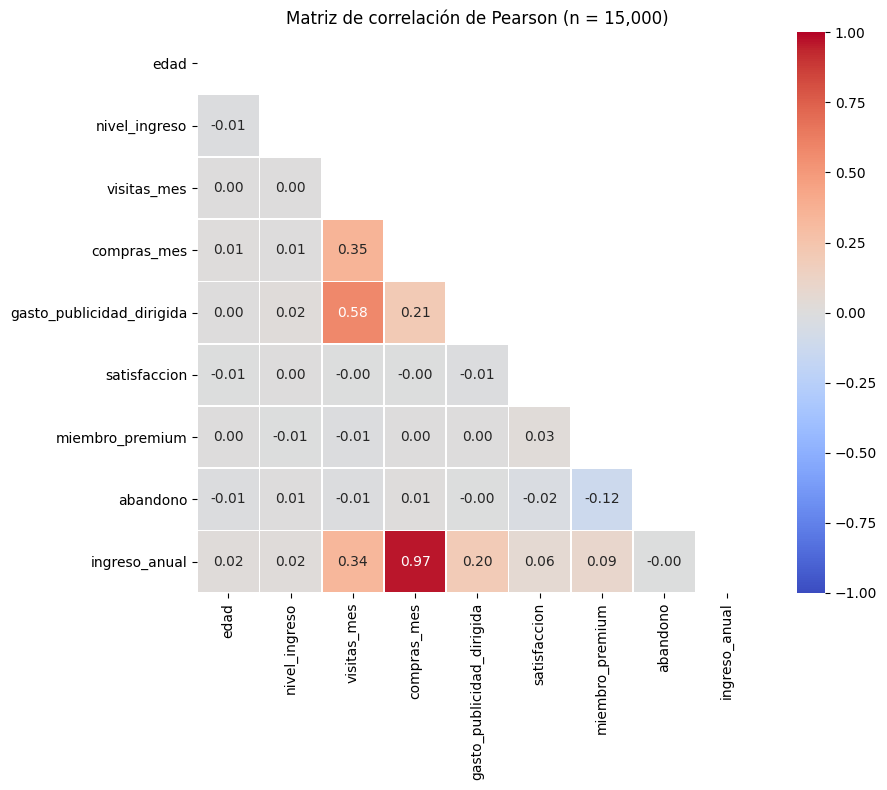

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_corr = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                 'gasto_publicidad_dirigida', 'satisfaccion',
                 'miembro_premium', 'abandono', 'ingreso_anual']

corr = df[columnas_corr].corr(method='pearson')
mascara = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title('Matriz de correlación de Pearson (n = 15,000)')
plt.tight_layout()
plt.show()


✍️ **Comentario:**

**Observaciones generales (Heatmap)**

* Se observa que la mayoría de las variables tiene correlaciones cercanas a 0 entre sí, lo que indica poca relación lineal entre ellas. Las excepciones más claras son `gasto_publicidad_dirigida` con `visitas_mes` (0.58), `visitas_mes` con `compras_mes` (0.35) y `gasto_publicidad_dirigida` con `compras_mes` (0.21).
* La alta correlación entre el gasto en publicidad y las visitas sugiere que la publicidad se asigna principalmente a los clientes más activos, lo que puede generar relaciones engañosas con el ingreso.
* Entre las variables binarias, `miembro_premium` y `abandono` muestran una relación débil negativa (-0.12): los clientes premium abandonan algo menos.
* `edad`, `nivel_ingreso` y `satisfaccion` no muestran relaciones lineales relevantes con las demás variables.

**Observaciones respecto a `ingreso_anual`**

* Presenta una correlación muy alta con `compras_mes` (0.97). Es una relación casi mecánica: cada compra aporta un monto similar de ingreso y los clientes sin compras tienen ingreso 0.
* Con `visitas_mes` (0.34) y `gasto_publicidad_dirigida` (0.20) la asociación es moderada a débil. En el caso de las visitas, parte de la relación pasa por las compras.
* `miembro_premium` (0.09) y `satisfaccion` (0.06) muestran asociaciones muy débiles.
* `edad` (0.02), `nivel_ingreso` (0.02) y `abandono` (-0.00) prácticamente no tienen relación lineal con el ingreso. En particular, lo que gana el cliente no predice cuánto ingreso genera para la empresa.
* Estos resultados son correlacionales y no implican causalidad.


### Scatterplot general

**Decisión:** se incluye un scatterplot general porque Pearson y Spearman solo capturan relaciones lineales o monotónicas; el gráfico permite verificar que las correlaciones cercanas a 0 no esconden patrones no lineales.

**Observaciones:**
- `compras_mes` muestra una relación positiva clara y casi lineal con `ingreso_anual` (r = 0.97), con los puntos agrupados en bandas por número de compras.
- `gasto_publicidad_dirigida` muestra una tendencia positiva débil con alta dispersión (r = 0.20).
- `satisfaccion`, `nivel_ingreso` y `edad` forman nubes sin patrón visible: no hay tendencia lineal ni curva (r ≤ 0.06), lo que confirma que no se relacionan con el ingreso.
- En todos los gráficos hay una franja de clientes con `ingreso_anual` = 0 (clientes sin compras).
- Esto confirma visualmente los coeficientes de la Sección 4.



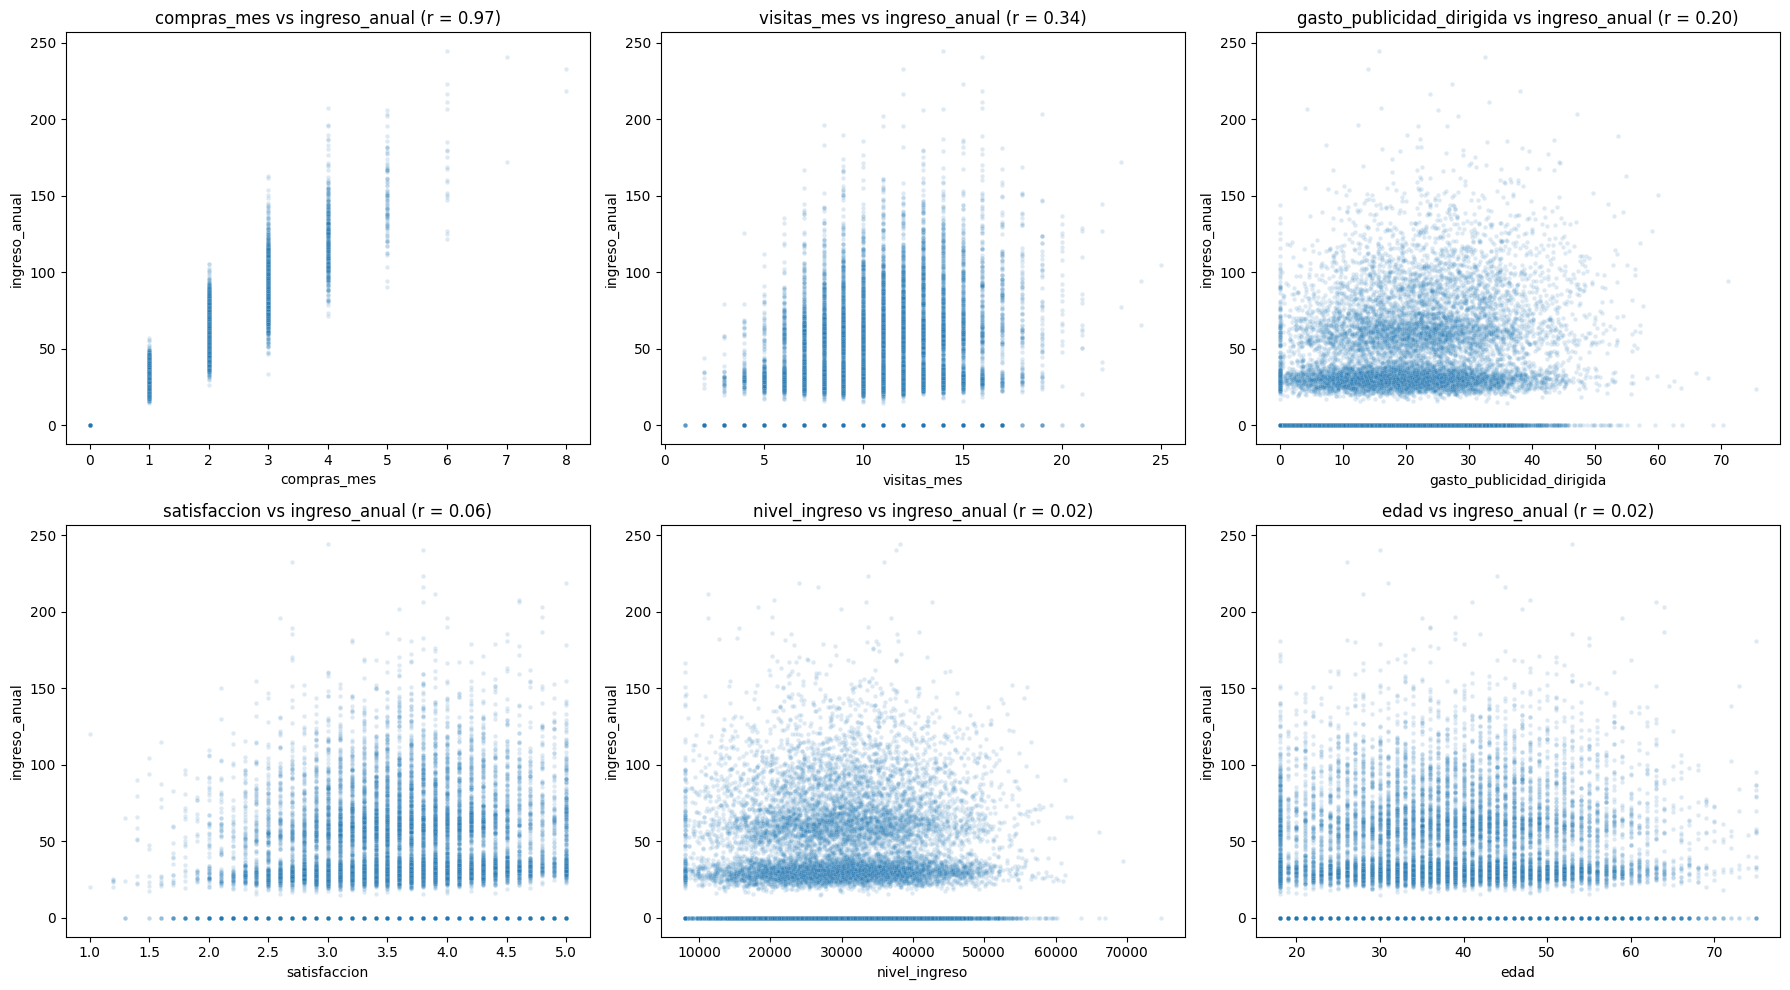

In [ ]:
# Scatterplot general: cada variable numérica vs ingreso_anual
variables = ['compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida',
             'satisfaccion', 'nivel_ingreso', 'edad']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, var in zip(axes.flatten(), variables):
    sns.scatterplot(data=df, x=var, y='ingreso_anual', alpha=0.15, s=10, ax=ax)
    r = df[var].corr(df['ingreso_anual'])
    ax.set_title(f'{var} vs ingreso_anual (r = {r:.2f})')

plt.tight_layout()
plt.show()

### Scatterplot para pares clave

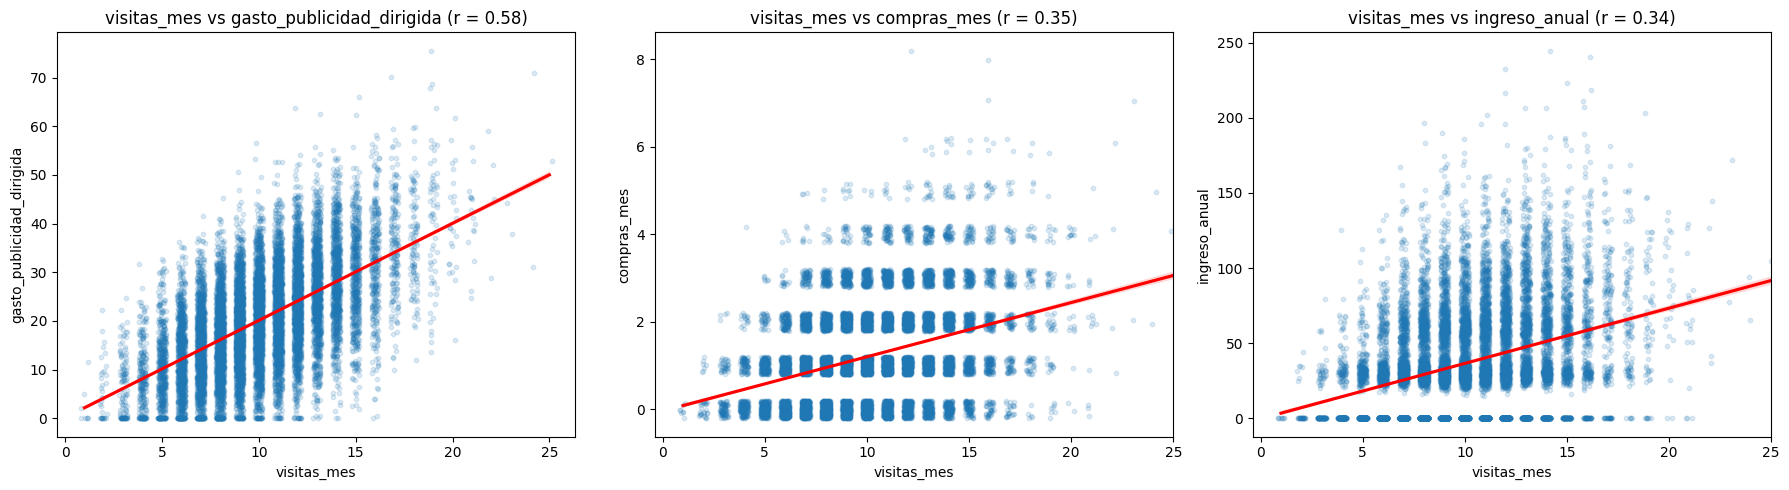

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
pares_moderados = [
    ('visitas_mes', 'gasto_publicidad_dirigida'),
    ('visitas_mes', 'compras_mes'),
    ('visitas_mes', 'ingreso_anual'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (x, y) in zip(axes, pares_moderados):
    sns.regplot(data=df, x=x, y=y, ax=ax,
                x_jitter=0.2,
                y_jitter=0.2 if y == 'compras_mes' else 0,
                scatter_kws={'alpha': 0.15, 's': 10},
                line_kws={'color': 'red'})
    r = df[x].corr(df[y])
    ax.set_title(f'{x} vs {y} (r = {r:.2f})')

plt.tight_layout()
plt.show()


✍️ **Comentario:**

**Observaciones iniciales (Scatterplot)**

`visitas_mes` vs `gasto_publicidad_dirigida` (r = 0.58)

* Dirección: positiva; a más visitas, mayor gasto publicitario asignado.
* Dispersión: media. La nube sigue la línea de tendencia, pero se abre a medida que aumentan las visitas (la variabilidad del gasto es mayor en clientes con muchas visitas).
* Outliers: algunos clientes con gasto superior a 60 y pocos con más de 20 visitas; son valores aislados y plausibles.
* Posible colinealidad: es la pareja más correlacionada entre las variables explicativas, por lo que `visitas_mes` y `gasto_publicidad_dirigida` aportan información parcialmente redundante. Sugiere que la publicidad se dirige a los clientes más activos.

`visitas_mes` vs `compras_mes` (r = 0.35)

* Dirección: positiva, con una pendiente suave.
* Dispersión: alta. Con cualquier nivel de visitas hay clientes con 0 compras, y también con 3 o más. Visitar más no garantiza comprar más.
* Outliers: pocos clientes con 7 u 8 compras; `compras_mes` es una variable discreta, por eso los puntos se ven en filas horizontales.
* Posible colinealidad: moderada-baja; las variables comparten información pero no son redundantes.

`visitas_mes` vs `ingreso_anual` (r = 0.34)

* Dirección: positiva.
* Dispersión: alta, con forma de abanico: la variabilidad del ingreso aumenta con las visitas.
* Outliers: algunos clientes con ingreso cercano a 250, muy por encima del resto, aunque coherentes con quienes tienen más compras.
* Se observa una franja de clientes con `ingreso_anual` = 0 en todos los niveles de visitas: son clientes que visitan la plataforma pero no compran. Esto reduce la correlación lineal.
* Parte de la asociación se explica porque quienes visitan más tienden a comprar más.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
numericas = ['compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida',
             'satisfaccion', 'nivel_ingreso', 'edad']

pearson = df[numericas + ['ingreso_anual']].corr(method='pearson')['ingreso_anual']
spearman = df[numericas + ['ingreso_anual']].corr(method='spearman')['ingreso_anual']

resultados = pd.DataFrame({'Pearson': pearson, 'Spearman': spearman}).drop('ingreso_anual')
resultados.sort_values('Pearson', ascending=False).round(3)


,Pearson,Spearman
compras_mes,0.967,0.967
visitas_mes,0.337,0.321
gasto_publicidad_dirigida,0.197,0.185
satisfaccion,0.056,0.061
edad,0.017,0.016
nivel_ingreso,0.017,0.025


✍️ **Comentario:**

**Observaciones de correlación**

`ingreso_anual` vs `compras_mes`

* Correlación positiva y muy fuerte (Pearson = 0.967, Spearman = 0.967). A más compras en el mes, mayor ingreso anual.
* Magnitud: casi perfecta. La relación es en gran parte mecánica, porque cada compra aporta un monto similar de ingreso y los clientes sin compras tienen ingreso 0.
* Colinealidad: es la variable que más se parece al ingreso, por lo que cualquier otra variable que se asocie con las compras (como las visitas) también lo hará, de forma indirecta, con el ingreso.

`ingreso_anual` vs `visitas_mes`

* Correlación positiva y moderada a débil (Pearson = 0.337, Spearman = 0.321).
* Magnitud: moderada. Los clientes que visitan más tienden a generar más ingreso, pero con mucha dispersión.
* Colinealidad: `visitas_mes` se relaciona con `compras_mes` (0.35) y con `gasto_publicidad_dirigida` (0.58), por lo que parte de su asociación con el ingreso pasa por esas variables.

`ingreso_anual` vs `gasto_publicidad_dirigida`

* Correlación positiva y débil (Pearson = 0.197, Spearman = 0.185).
* Magnitud: débil. La relación puede ser engañosa: la publicidad parece asignarse a los clientes más activos (más visitas), y no necesariamente generar el ingreso.
* Colinealidad: es la pareja más correlacionada entre las variables explicativas (0.58 con `visitas_mes`, según el heatmap).

`ingreso_anual` vs `satisfaccion`, `edad` y `nivel_ingreso`

* Correlaciones prácticamente nulas (entre 0.016 y 0.061 en ambos coeficientes). Aunque algunos p-values sean pequeños, es efecto del tamaño de muestra (15,000) y no una relación relevante.
* Pearson y Spearman son casi idénticos en todas las variables, lo que indica que la asimetría del ingreso y los valores extremos no distorsionan los resultados

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
for col in ['miembro_premium', 'abandono']:
    r, p = pointbiserialr(df[col], df['ingreso_anual'])
    print(f"{col}: r = {r:.3f}, p = {p:.2g}")
    print("Ingreso anual promedio por grupo:", df.groupby(col)['ingreso_anual'].mean().round(2).to_dict())
    print()


miembro_premium: r = 0.093, p = 3.1e-30
Ingreso anual promedio por grupo: {0: 35.3, 1: 44.58}

abandono: r = -0.003, p = 0.73
Ingreso anual promedio por grupo: {0: 36.64, 1: 36.36}



✍️ **Comentario:**

**Observaciones Punto-biserial**

`ingreso_anual` vs `miembro_premium`

* Relación positiva y débil (r = 0.093). Los clientes premium generan en promedio más ingreso anual que los no premium (44.58 frente a 35.30, unas 9 unidades más).
* La asociación es estadísticamente significativa (p < 0.001), pero su magnitud es baja. Además, solo el 13.9% de los clientes es premium, por lo que el grupo comparado es mucho más pequeño.
* Con estos datos no se puede afirmar que la suscripción cause un mayor ingreso: los clientes más comprometidos pueden ser, a la vez, quienes se suscriben y quienes compran más.

`ingreso_anual` vs `abandono`

* Relación prácticamente nula (r = -0.003, p = 0.73), sin significancia estadística.
* El ingreso promedio de quienes abandonaron (36.36) y de quienes siguen activos (36.64) es casi idéntico: el ingreso anual no distingue entre ambos grupos

### V de Cramér

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
# Función para calcular V de Cramér
def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
    return round(v, 3), p

In [ ]:
# Aplicar V de Cramér en variables relevantes
# ingreso_anual se convierte en 4 segmentos (cuartiles) para compararlo con categóricas.
# Se usa rank porque hay muchos ceros y qcut directo fallaría por bordes repetidos.
df['segmento_ingreso'] = pd.qcut(df['ingreso_anual'].rank(method='first'),
                                 q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

pares = [('tipo_dispositivo', 'segmento_ingreso'),
         ('region', 'segmento_ingreso'),
         ('tipo_dispositivo', 'region'),
         ('tipo_dispositivo', 'abandono'),
         ('region', 'abandono'),
         ('tipo_dispositivo', 'miembro_premium'),
         ('region', 'miembro_premium')]

resultados_v = []
for a, b in pares:
    v, p = cramers_v(df[a], df[b])
    resultados_v.append({'variable_1': a, 'variable_2': b, 'V_Cramer': v, 'p_value': round(p, 3)})

pd.DataFrame(resultados_v)


,variable_1,variable_2,V_Cramer,p_value
0,tipo_dispositivo,segmento_ingreso,0.016,0.285
1,region,segmento_ingreso,0.016,0.212
2,tipo_dispositivo,region,0.012,0.596
3,tipo_dispositivo,abandono,0.007,0.675
4,region,abandono,0.015,0.312
5,tipo_dispositivo,miembro_premium,0.020,0.054
6,region,miembro_premium,0.013,0.499


✍️ **Comentario:**

**Observaciones V de Cramér**

* Todas las asociaciones entre variables categóricas son prácticamente nulas: los valores de V están entre 0.007 y 0.020, y ningún p-value es menor a 0.05.
* `tipo_dispositivo` (V = 0.016, p = 0.285) y `region` (V = 0.016, p = 0.212) no se asocian con el segmento de ingreso: el dispositivo y la región no distinguen entre clientes de bajo y alto ingreso.
* `tipo_dispositivo` y `region` tampoco se asocian entre sí (V = 0.012), por lo que no hay colinealidad entre ellas.
* El `abandono` no se concentra en ningún dispositivo (V = 0.007) ni región (V = 0.015).
* La combinación más cercana a la significancia es `tipo_dispositivo` con `miembro_premium` (V = 0.020, p = 0.054), pero con una V tan baja no tiene relevancia práctica.
* Estos resultados son correlacionales y no implican causalidad


## Sección 5 - Interpretación de resultados para el negocio

---

## 5. Interpretación de resultados para el negocio

### 5.1. Hallazgo 1 — Las compras mensuales son, con diferencia, lo más asociado con el ingreso anual

**Evidencia visual:** en el heatmap, `compras_mes` vs `ingreso_anual` es la celda más intensa (0.97). En el scatterplot, los puntos forman bandas por número de compras y el ingreso sube de forma casi proporcional; los clientes con 0 compras están todos en `ingreso_anual` = 0.

**Evidencia numérica:** Pearson = 0.967 y Spearman = 0.967. El ingreso promedio es 0 con 0 compras, ≈ 30 con 1 compra, ≈ 61 con 2 y ≈ 91 con 3. El 30.4% de los clientes (4,567) tiene 0 compras e ingreso 0.

**Interpretación:** los clientes que compran más generan más ingreso, y la relación es casi proporcional. Es una asociación en parte mecánica, porque el ingreso se construye a partir de las compras: cada compra aporta un monto similar.

**No podemos afirmar:** que esta correlación sea un descubrimiento de comportamiento ni que sirva para explicar *por qué* unos clientes generan más. Tampoco que aumentar las compras de un cliente en particular aumente su ingreso en la misma proporción en todos los casos.

**Implicación de negocio:** el ingreso depende sobre todo de lograr que el cliente compre. La prioridad para Crecimiento y Retención debería ser convertir a los clientes sin compras (30% de la base) y aumentar la frecuencia de compra de quienes ya compran.

### 5.2. Hallazgo 2 — Visitas y publicidad dirigida se asocian con el ingreso, pero de forma moderada a débil y entrelazada

**Evidencia visual:** en los scatterplots, `visitas_mes` vs `ingreso_anual` muestra una tendencia positiva con mucha dispersión y una franja de clientes con ingreso 0 en todos los niveles de visitas. `gasto_publicidad_dirigida` vs `visitas_mes` muestra una tendencia positiva más clara.

**Evidencia numérica:** `visitas_mes` vs `ingreso_anual`: Pearson = 0.337, Spearman = 0.321. `gasto_publicidad_dirigida` vs `ingreso_anual`: Pearson = 0.197, Spearman = 0.185. Entre sí, `gasto_publicidad_dirigida` y `visitas_mes` tienen 0.58; `visitas_mes` y `compras_mes`, 0.35.

**Interpretación:** los clientes que visitan más tienden a generar más ingreso, pero con mucha variabilidad: visitar no garantiza comprar. La publicidad dirigida se asocia con el ingreso de forma débil y es posible que se asigne principalmente a los clientes más activos, de modo que parte de la relación se explique por las visitas y las compras.

**No podemos afirmar:** que más visitas causen más ingreso, ni que la publicidad dirigida genere ingreso. La relación con la publicidad podría ser inversa (se invierte más en clientes que ya valen más) o estar explicada por una tercera variable (la actividad del cliente).

**Implicación de negocio:** las visitas por sí solas no son un buen indicador de valor; conviene mirar si se convierten en compras. Antes de aumentar la inversión en publicidad dirigida, se recomienda evaluarla con un experimento controlado (por ejemplo, un A/B test), porque estos datos no permiten medir su efecto.

### 5.3. Hallazgo 3 — La membresía premium se asocia débilmente con mayor ingreso

**Evidencia visual:** en el heatmap, `miembro_premium` vs `ingreso_anual` tiene un valor bajo (0.09).

**Evidencia numérica:** punto biserial r = 0.093 (p < 0.001). Ingreso promedio de 44.58 en clientes premium frente a 35.30 en no premium. Solo el 13.9% de los clientes es premium.

**Interpretación:** los clientes premium generan en promedio unas 9 unidades más de ingreso, pero la asociación es débil.

**No podemos afirmar:** que la suscripción premium cause un mayor ingreso. Los clientes más comprometidos pueden ser los que se suscriben y los que más compran.

**Implicación de negocio:** el programa premium puede valer la pena explorarlo, pero la evidencia no justifica una inversión grande por sí sola. Conviene probar su efecto con un piloto o experimento.

### 5.4. Hallazgo 4 — Variables demográficas y de segmentación no explican el ingreso ni el abandono

**Evidencia visual:** en el heatmap, `edad`, `nivel_ingreso` y `abandono` tienen valores cercanos a 0 respecto a `ingreso_anual`.

**Evidencia numérica:** `edad` (0.017), `nivel_ingreso` (0.017), `satisfaccion` (0.056) y `abandono` (-0.003) frente a `ingreso_anual`. V de Cramér entre 0.007 y 0.020 para `tipo_dispositivo` y `region` frente al ingreso y el abandono; ingreso promedio entre 35.7 y 37.1 en todas las categorías.

**Interpretación:** el ingreso que genera un cliente no depende de su edad, de cuánto gane, de su dispositivo ni de su región. El abandono tampoco se concentra en clientes de mayor o menor ingreso.

**No podemos afirmar:** que estas variables sean irrelevantes para otros objetivos (por ejemplo, para el comportamiento de compra o la retención), ni que no existan relaciones no lineales o interacciones entre ellas.

**Implicación de negocio:** segmentar campañas por edad, nivel de ingreso, dispositivo o región no parece una buena palanca para aumentar el ingreso por cliente. Es mejor segmentar por comportamiento (compras y visitas).


## Sección 6 - Limitaciones y próximos pasos

## 6. Limitaciones y próximos pasos

### 6.1. Limitaciones

* **Correlación ≠ causalidad.** Todos los resultados son asociaciones; no permiten afirmar que una variable cause cambios en el ingreso.
* **Relación casi mecánica entre compras e ingreso.** El 30.4% de los clientes tiene `compras_mes` = 0 e `ingreso_anual` = 0, y cada compra aporta ~30 unidades. La correlación de 0.97 refleja cómo se construye el ingreso, y no necesariamente un comportamiento del cliente.
* **Posible causalidad inversa y variables ocultas en la publicidad.** `gasto_publicidad_dirigida` no se asigna al azar: se correlaciona con las visitas (0.58), lo que sugiere que se dirige a clientes ya activos. Su asociación con el ingreso (0.20) no mide el efecto de la publicidad.
* **Desajuste temporal entre variables.** `visitas_mes` y `compras_mes` son medidas de un mes, mientras que `ingreso_anual` es un acumulado anual; no sabemos si el comportamiento de un mes representa el del año.
* **Solo un periodo (2024) y una fotografía por cliente.** No hay dimensión temporal, por lo que no se puede ver cómo evoluciona el comportamiento ni qué ocurre antes o después del abandono.
* **Coeficientes de correlación simples.** Pearson y Spearman miden relaciones entre pares de variables y no controlan por el resto. No se evaluaron interacciones ni relaciones no lineales más complejas.
* **Muchos ceros y asimetría en `ingreso_anual`.** Esto reduce la correlación lineal de las demás variables y puede ocultar patrones entre quienes sí compran.
* **Efecto techo en `satisfaccion`.** Hay un pico en 5.0 (420 clientes frente a 157 con 4.9), lo que puede distorsionar la relación con otras variables.
* **Cuartiles de ingreso para la V de Cramér.** Convertir `ingreso_anual` en cuatro segmentos pierde información, y Q1 está formado casi por completo por clientes sin compras.
* **Inconsistencia en el enunciado.** El enunciado menciona `ingresos_mensuales` como métrica foco, que no existe en el dataset; se asumió `ingreso_anual`.
* **Significancia estadística vs. relevancia práctica.** Con 15,000 clientes, correlaciones muy pequeñas (≈ 0.02) pueden salir significativas sin tener importancia para el negocio.

### 6.2. Próximos pasos

**Probar segmentación adicional**

* Analizar por separado a los clientes que compraron (≈ 10,400) y a los que no (≈ 4,600), para ver qué los distingue.
* Cruzar variables de comportamiento con `miembro_premium` y `tipo_dispositivo` (por ejemplo, ¿los premium convierten más visitas en compras?).

**Separar los efectos de visitas, publicidad y compras**

* Calcular correlaciones parciales o ajustar un modelo de regresión múltiple para estimar la asociación de cada variable con el ingreso controlando por las demás.
* Analizar el ingreso por compra (ingreso / compras) para ver si hay diferencias de valor más allá de la cantidad de compras.

**Medir el efecto causal de la publicidad y del premium**

* Diseñar un experimento controlado (A/B test) que asigne la publicidad dirigida de forma aleatoria, para medir su efecto real sobre las compras y el ingreso.
* Evaluar con un piloto si ofrecer la membresía premium a un grupo de clientes aumenta su ingreso frente a un grupo de comparación.

**Mejorar los datos disponibles**

* Incorporar datos por mes durante 2024 o de varios años, para estudiar la evolución y las cohortes de clientes.
* Revisar cómo se mide `satisfaccion` (escala truncada en 5) y confirmar con el equipo de datos cuál era la métrica foco prevista.